# 2023년 1학기 웹/파이선 텀프로젝트

## 1. 주제
    1) 주제 : 해외축구선수의 몸값과 나이,이번 시즌 골 수의 상관관계 분석
    2) 선정이유 : 평소에 해외축구에 매우 관심이 많은데, 해외축구를 보면서 생겼던 궁금증을 데이터분석을 통해 해결하기 위해 선정하였다.

## 2.가설 혹은 명제
    1) 대체로 공격수가 몸값이 비쌀 것이다.
    2) 대체로 나이가 많은 선수보다 나이가 적은 선수들의 몸값이 비쌀 것이다.
    3) 골 수가 많은 공격수들이 몸값이 비쌀 것이다.


## 3.분석할 데이터의 출처와 데이터 내용

1) 데이터의 출처 : [전세계선수들의 몸값을 평가하는 transfermarkt의 데이터](https://www.transfermarkt.com/spieler-statistik/wertvollstespieler/marktwertetop?land_id=0&ausrichtung=alle&spielerposition_id=alle&altersklasse=alle&jahrgang=0&kontinent_id=0&plus=1)

2) 데이터 내용 : 선수300명의  이름, 몸값 순위, 포지션, 나이 , 몸값, 경기 수 ,골 수

3) 데이터 수집, 가공 방법 : 웹사이트에서 필요한 데이터만 파싱하여 위의 데이터내용을 컬럼으로갖는 pandas dataframe으로 정리(코드는 아래와 같음) -> 엑셀파일로 저장


In [33]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

headers = {'User-Agent':'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/113.0.0.0 Safari/537.36'}
value_rank=[] #선수의 정보 저장할 데이터 리스트
name=[]
position=[]
age=[]
value=[]
matches=[]
goals=[] 
for i in range(1, 13): #페이지당 25명의선수데이터 ->총 300명데이터불러오기
    url = f"https://www.transfermarkt.com/spieler-statistik/wertvollstespieler/marktwertetop?land_id=0&ausrichtung=alle&spielerposition_id=alle&altersklasse=alle&jahrgang=0&kontinent_id=0&plus=1?ajax=yw1&page={i}"
    r = requests.get(url,headers=headers)
    soup = BeautifulSoup(r.content, 'html.parser') 

    player=soup.find_all('tr', class_=['odd', 'even'])
    for information in player:
        player_info = information.find_all("td")
        value_rank.append(player_info[0].text)
        name.append(player_info[3].text)
        position.append(player_info[4].text)
        age.append(player_info[5].text)
        value.append(player_info[8].text)
        matches.append(player_info[9].text)
        goals.append(player_info[10].text)

for j in range(len(value_rank)-1): # 선수몸값이 같으면 value_rank를 같은값으로 설정
    if value[j+1] == value[j]:
        value_rank[j+1] = value_rank[j]
        
for k in range(len(position)): #데이터 가공 --> 포지션 : 공격수,미드필더,수비수,골키퍼 네개로 분류하기
    if "Winger" in position[k] or "Forward" in position[k] or "Striker" in position[k]:
        position[k] = "Forward"
    elif "Midfield" in position[k]:
        position[k] = "Midfield"
    elif "Back" in position[k]:
        position[k] = "Defender"

pd.set_option('display.max_columns',None)
pd.set_option('display.max_row',None)
data = pd.DataFrame({"value_rank":value_rank,"name":name,"position":position,"age":age,"value":value,"matches":matches,"goals":goals})
data.to_excel("player_info.xlsx")

- 데이터 분석을 편하게 하기 위해 선수들의 몸값에서 유로기호와 100만을 나타내는 m기호, 그리고 소수점이 모두 0이므로 소수점을 삭제시켰다(엑셀 찾기및바꾸기 기능을 통해)

In [2]:
import pandas as pd
pd.read_excel('player_info.xlsx')  #최종적으로 사용할 데이터 (엑셀파일을 pandas로 불러옴)

,Unnamed: 0,value_rank,name,position,age,value,matches,goals
0,0,1,Kylian Mbappé,Forward,24,180,50,45
1,1,2,Erling Haaland,Forward,22,170,59,58
2,2,3,Jude Bellingham,Midfield,19,120,49,14
3,3,3,Vinicius Junior,Forward,22,120,58,23
4,4,5,Jamal Musiala,Midfield,20,110,53,16
...,...,...,...,...,...,...,...,...
295,295,286,Anthony Elanga,Forward,21,25,34,2
296,296,286,Youssouf Fofana,Midfield,24,25,50,2
297,297,286,Gonçalo Inácio,Defender,21,25,55,4
298,298,286,Max Kilman,Defender,26,25,41,0


## 4.분석 결과


### 가설 1 : 대체로 공격수가 몸값이 비쌀 것이다.

In [3]:
df = pd.read_excel('player_info.xlsx') 
df['value'] = df['value'].astype(int)  # value(몸값) int형으로 바꾸기
df1 = df[['position','value']] #선수들의 포지션과 몸값데이터만 추출해서 불러오기
print(df1)

     position  value
0     Forward    180
1     Forward    170
2    Midfield    120
3     Forward    120
4    Midfield    110
..        ...    ...
295   Forward     25
296  Midfield     25
297  Defender     25
298  Defender     25
299  Defender     25

[300 rows x 2 columns]


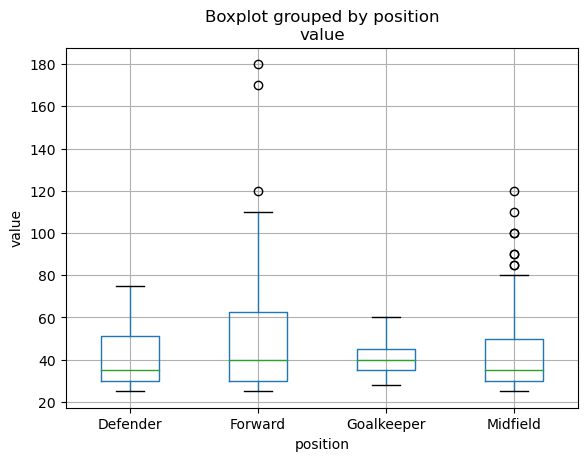

In [102]:
import matplotlib.pyplot as plt
boxplot1 = df1.boxplot(column=['value'],by='position') #각 포지션별 몸값을 박스플롯으로 나타내기
plt.ylabel('value')
boxplot1.plot()
plt.show()

- 그래프를 통해 수비수와 미드필더보다 골키퍼와 공격수의 중간값이 높음을 확인할 수 있다.
- 공격수에서 몸값이 중간값 이상에 분포하는 선수가 많음으로보아서 공격수가 대체로 몸값이 비쌈을 확인할 수 있다.
- 75%에 해당하는 3분위값이 공격수만 60이 넘음을 확인할 수 있다. 
- 최댓값과 outlier값이 공격수가 다른 포지션에 비해 높음을 확인할 수 있다.

### 가설 2 : 대체로 나이가 많은 선수보다 나이가 적은 선수들의 몸값이 비쌀 것이다.

- 나이대와 몸값의 상관관계를 분석하기 위해서 데이터를 그룹별로 묶어서 가공하였다.
- A(20세이하), B(21~24세),C(25~28세),D(29~31세),E(32세이상)

In [64]:
df['age'] = df['age'].astype(int)  # age(나이) int형으로 바꾸기
df2 = df[['age','value']]
df2['group'] = None #group 열추가
df2.loc[df['age']<=20,'group']='A(~20)'
df2.loc[(df['age']>20)&(df['age']<25),'group']='B(21~24)'
df2.loc[(df['age']>25)&(df['age']<29),'group']='C(25~28)'
df2.loc[(df['age']>29)&(df['age']<32),'group']='D(29~31)'
df2.loc[(df['age']>32),'group']='E(32~)'
print(df2)

     age  value     group
0     24    180  B(21~24)
1     22    170  B(21~24)
2     19    120    A(~20)
3     22    120  B(21~24)
4     20    110    A(~20)
..   ...    ...       ...
295   21     25  B(21~24)
296   24     25  B(21~24)
297   21     25  B(21~24)
298   26     25  C(25~28)
299   20     25    A(~20)

[300 rows x 3 columns]


C:\Users\이강훈\AppData\Local\Temp\ipykernel_34808\3803618685.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['group'] = None #group 열추가


- 그룹별로 몸값을 평균내서 데이터를 추출하였다.

In [71]:
group_df = df2.groupby('group')['value'].mean() #그룹별 몸값 평균내기
print(group_df)

group
A(~20)      45.920000
B(21~24)    49.460177
C(25~28)    42.284091
D(29~31)    44.826087
E(32~)      40.000000
Name: value, dtype: float64


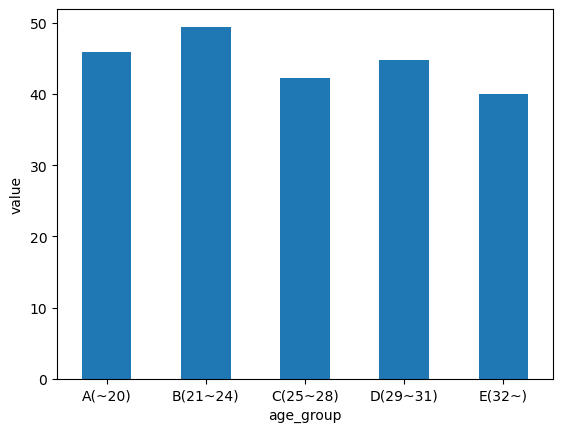

In [97]:
group_df.plot.bar(x='group',y='value',rot=0)
plt.xlabel('age_group')
plt.ylabel('value')
plt.show()

- 그래프를 통해서 21~24세 그룹의 평균 몸값이 가장높고, 32세이상 그룹의 평균 몸값이 가장 낮음을 확인할 수 있다.
- 20세이하 그룹의 평균 몸값도 C,D,E 그룹보다 높음을 확인할 수 있다.
- 예외적으로 D그룹이 C그룹보다 나이가 많음에도 불구하고 몸값이 대체로 높음을 확인할 수 있다.


### 가설 3 : 골 수가 많은 공격수들이 몸값이 비쌀 것이다.

In [92]:
df3_1 = df[df['position'] == "Forward"] #공격수 데이터만 추출
df3_2 = df3_1[['goals','value']] #공격수 데이터중 골수와 몸값만 추출
print(df3_2)

     goals  value
0       45    180
1       58    170
3       23    120
5       16    110
6       15    110
..     ...    ...
287      4     25
288     10     25
290     20     25
294      7     25
295      2     25

[99 rows x 2 columns]


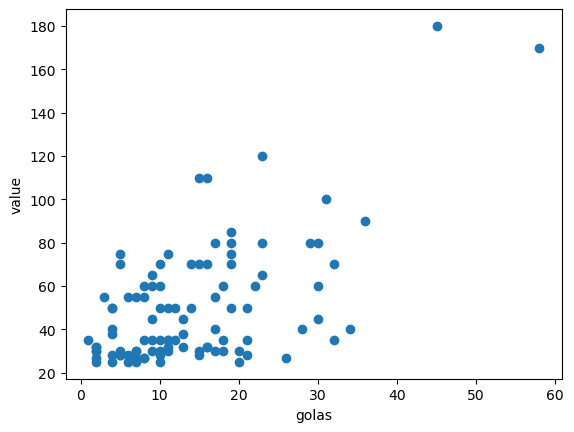

In [96]:
plt.scatter(df3_2['goals'],df3_2['value'])
plt.xlabel('golas')
plt.ylabel('value')
plt.show()

- 골수가 0~15정도에 머무르는 공격수들은 몸값이 대체로 낮게 분포되어있음을 확인할 수 있다.
- 골수가 20~30골이어도 몸값이 낮은 선수들도 많음을 확인할 수 있다.


## 5. 결론

- 포지션과 몸값의 상관관계(대체로 공격수가 몸값이 비쌀 것이다.)
    - 공격수 몸값의 중간값과 3분위값 그리고 ouliter값이 모두 제일 높으므로 대체로 공격수가 몸값이 비싸다는 가설이 맞음을 입증할 수 있다.



- 몸값과 나이의 상관관계(대체로 나이가 많은 선수보다 나이가 적은 선수의 몸값이 비쌀 것이다.)
    - 몸값이 가장 높은 그룹이 21~24세,두번째로 높은 그룹이 20세이하, 가장 낮은 그룹이 32세 이상이므로 어린선수가 나이많은 선수들에비해 몸값이 높다.
    - 하지만 29~31세의 선수들이 25~28세 선수들 보다 몸값이 높은 현상으로 보아 이 가설이 전반적으로 모든 연령대에 성립하지 않는다.

    

- 골 수와 몸값의 상관관계(골 수가 많은 공격수들이 몸값이 비쌀 것이다.)
    - 골 수가 낮은 선수들의 대부분이 몸값이 낮다.
    - 하지만 골 수가 낮아도 골 수가 높은 선수들 보다 몸값이 비싼 선수도 적지 않음으로 보아서, 이 가설은 성립하지 않는다.
    - 골 수가 몸값에 영향을 끼칠 수는 있지만 직접적으로 바로 연관되지는 않음을 확인할 수 있다.

## 6. 참고 문헌
- https://wikidocs.net/book/5011
- https://jimmy-ai.tistory.com/34
- https://gecko-ari.tistory.com/205
- https://library.gabia.com/contents/9239/